# SVM vs k-NN vs Decision Tree - Manual Metrics, Boundaries, Trade-offs

## Compare SVM, k-NN, and Decision Tree models by manually computing and visualizing performance metrics such as accuracy, precision, recall, and decision boundaries, ensuring a deep analysis of model trade-offs and real-world applicability.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_classification
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [2]:
def split(X, y, test=0.3, seed=0):
    r = np.random.default_rng(seed); idx = r.permutation(len(X)); s = int((1 - test) * len(X))
    return X[idx[:s]], y[idx[:s]], X[idx[s:]], y[idx[s:]]

def standardize(Xtr, Xte):
    mu, sd = Xtr.mean(0), Xtr.std(0)                     
    return (Xtr - mu) / sd, (Xte - mu) / sd

def confusion(y, p):
    tp = np.sum((p == 1) & (y == 1)); fp = np.sum((p == 1) & (y == 0))
    fn = np.sum((p == 0) & (y == 1)); tn = np.sum((p == 0) & (y == 0))
    return tp, fp, fn, tn

def metrics(y, p):
    tp, fp, fn, tn = confusion(y, p)
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if tp + fp else 0.0          
    rec = tp / (tp + fn) if tp + fn else 0.0            
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(acc=acc, prec=prec, rec=rec, f1=f1)

In [3]:
X, y = make_moons(n_samples=600, noise=0.3, random_state=1)
Xtr, ytr, Xte, yte = split(X, y, seed=1)
Xtr, Xte = standardize(Xtr, Xte)

def get_models():
    return {'SVM (RBF)':      SVC(kernel='rbf', C=1.0, gamma='scale'),
            'k-NN (k=5)':     KNeighborsClassifier(n_neighbors=5),
            'Decision Tree':  DecisionTreeClassifier(max_depth=5, random_state=0)}

models = get_models()
for m in models.values():
    m.fit(Xtr, ytr)

In [4]:
print(f"{'Model':15s} {'TP':>4s} {'FP':>4s} {'FN':>4s} {'TN':>4s} {'Acc':>6s} {'Prec':>6s} {'Rec':>6s} {'F1':>6s} {'Train acc':>10s}")
for name, m in models.items():
    p = m.predict(Xte); tp, fp, fn, tn = confusion(yte, p); r = metrics(yte, p)
    tr_acc = metrics(ytr, m.predict(Xtr))['acc']
    print(f"{name:15s} {tp:4d} {fp:4d} {fn:4d} {tn:4d} {r['acc']:6.3f} {r['prec']:6.3f} {r['rec']:6.3f} {r['f1']:6.3f} {tr_acc:10.3f}")

Model             TP   FP   FN   TN    Acc   Prec    Rec     F1  Train acc
SVM (RBF)         88   10    5   77  0.917  0.898  0.946  0.921      0.905
k-NN (k=5)        86    9    7   78  0.911  0.905  0.925  0.915      0.917
Decision Tree     88   16    5   71  0.883  0.846  0.946  0.893      0.914


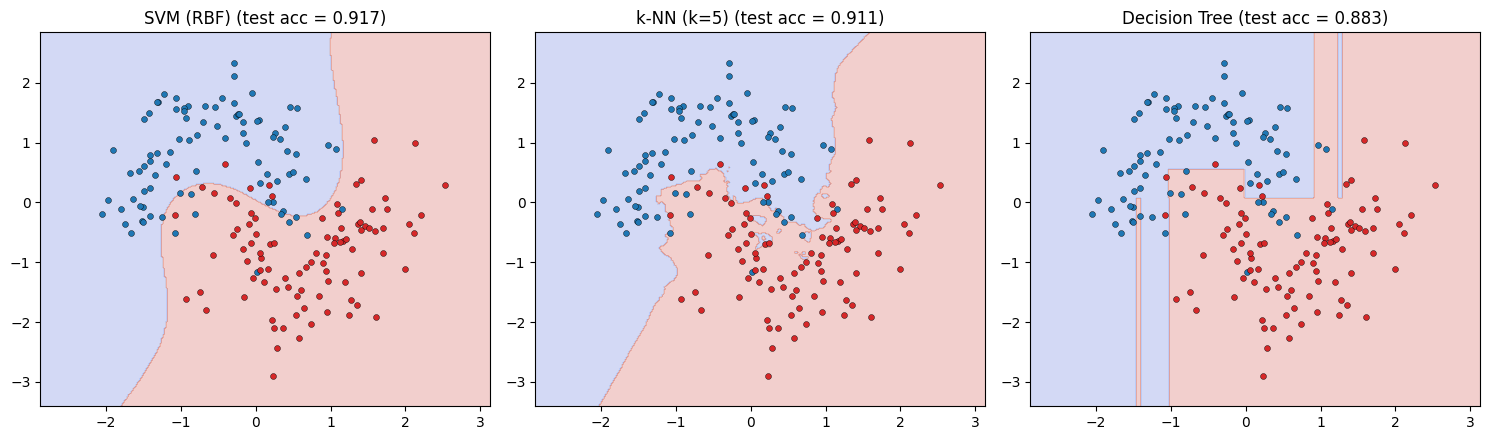

In [5]:
allX = np.vstack([Xtr, Xte])                            
gx, gy = np.meshgrid(np.linspace(allX[:, 0].min() - .5, allX[:, 0].max() + .5, 300),
                     np.linspace(allX[:, 1].min() - .5, allX[:, 1].max() + .5, 300))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, m) in zip(axes, models.items()):
    ax.contourf(gx, gy, m.predict(grid).reshape(gx.shape), alpha=0.25, cmap='coolwarm')
    ax.scatter(Xte[yte == 0, 0], Xte[yte == 0, 1], c='tab:blue', s=18, edgecolors='k', linewidths=0.3)
    ax.scatter(Xte[yte == 1, 0], Xte[yte == 1, 1], c='tab:red', s=18, edgecolors='k', linewidths=0.3)
    ax.set_title(f"{name} (test acc = {metrics(yte, m.predict(Xte))['acc']:.3f})")
plt.tight_layout(); plt.show()

In [6]:
Xb, yb = make_classification(n_samples=3000, n_features=10, n_informative=5, n_redundant=2,
                             weights=[0.85, 0.15], flip_y=0.03, class_sep=0.9, random_state=3)
Xb[:, 0] *= 1000                                         
print('Positive class share:', yb.mean().round(3))
print('Majority-class baseline accuracy:', round(1 - yb.mean(), 3))   

Positive class share: 0.158
Majority-class baseline accuracy: 0.842


In [7]:
def evaluate(scale, runs=10):
    out = {n: {'acc': [], 'prec': [], 'rec': [], 'f1': [], 'fit': [], 'pred': []} for n in get_models()}
    for seed in range(runs):
        Xa, ya, Xc, yc = split(Xb, yb, seed=seed)
        if scale: Xa, Xc = standardize(Xa, Xc)
        for name, m in get_models().items():
            t0 = time.time(); m.fit(Xa, ya); t1 = time.time(); p = m.predict(Xc); t2 = time.time()
            for k, v in metrics(yc, p).items(): out[name][k].append(v)
            out[name]['fit'].append(t1 - t0); out[name]['pred'].append(t2 - t1)
    return out

res_raw, res_scaled = evaluate(False), evaluate(True)

print(f"{'Model (standardized)':22s} {'Acc':>13s} {'Prec':>13s} {'Rec':>13s} {'F1':>13s}")
for name, r in res_scaled.items():
    f = lambda k: f"{np.mean(r[k]):.3f}+-{np.std(r[k]):.3f}"
    print(f"{name:22s} {f('acc'):>13s} {f('prec'):>13s} {f('rec'):>13s} {f('f1'):>13s}")

Model (standardized)             Acc          Prec           Rec            F1
SVM (RBF)               0.920+-0.006  0.943+-0.029  0.523+-0.026  0.672+-0.025
k-NN (k=5)              0.916+-0.010  0.895+-0.045  0.529+-0.044  0.664+-0.042
Decision Tree           0.899+-0.009  0.808+-0.045  0.479+-0.045  0.599+-0.033


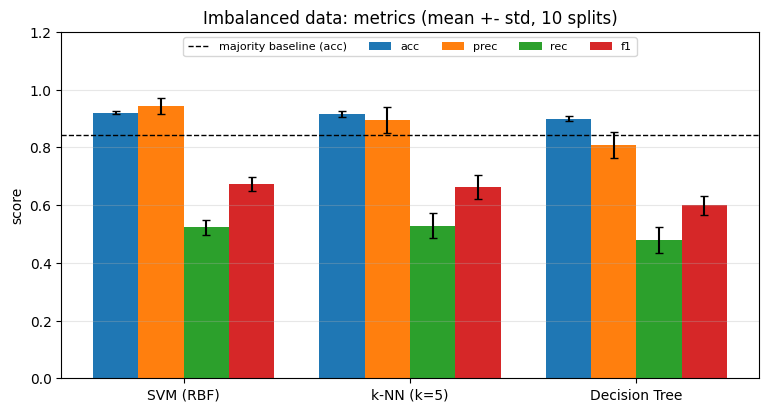

In [8]:
names, keys = list(res_scaled), ['acc', 'prec', 'rec', 'f1']
w = 0.2; xs = np.arange(len(names))
plt.figure(figsize=(9, 4.5))
for j, k in enumerate(keys):
    plt.bar(xs + j * w, [np.mean(res_scaled[n][k]) for n in names], w,
            yerr=[np.std(res_scaled[n][k]) for n in names], capsize=3, label=k)
plt.axhline(1 - yb.mean(), color='k', ls='--', lw=1, label='majority baseline (acc)')
plt.xticks(xs + 1.5 * w, names); plt.ylim(0, 1.2); plt.ylabel('score')
plt.title('Imbalanced data: metrics (mean +- std, 10 splits)'); plt.legend(ncol=5, fontsize=8, loc='upper center')
plt.grid(axis='y', alpha=0.3); plt.show()

In [9]:
print(f"{'Model':15s} {'F1 raw units':>13s} {'F1 scaled':>10s} {'Fit (s)':>9s} {'Predict (s)':>12s}")
for name in res_scaled:
    print(f"{name:15s} {np.mean(res_raw[name]['f1']):13.3f} {np.mean(res_scaled[name]['f1']):10.3f} "
          f"{np.mean(res_scaled[name]['fit']):9.4f} {np.mean(res_scaled[name]['pred']):12.4f}")

Model            F1 raw units  F1 scaled   Fit (s)  Predict (s)
SVM (RBF)               0.000      0.672    0.1481       0.1123
k-NN (k=5)              0.068      0.664    0.0092       0.0608
Decision Tree           0.599      0.599    0.0295       0.0006


In [10]:
print(f"{'depth':>5s} {'train acc':>10s} {'test acc':>9s}")
for d in [1, 2, 3, 5, 8, 12, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, ytr)
    print(f"{str(d):>5s} {metrics(ytr, t.predict(Xtr))['acc']:10.3f} {metrics(yte, t.predict(Xte))['acc']:9.3f}")

depth  train acc  test acc
    1      0.810     0.794
    2      0.902     0.883
    3      0.902     0.883
    5      0.914     0.883
    8      0.962     0.889
   12      0.990     0.872
 None      1.000     0.883


## Analysis
(Apne run ke numbers dekhke yahan 2-3 line apne words me zaroor likho. Neeche mere run ke numbers hain, tumhare run me thoda farak aa sakta hai.)

**1. Decision boundaries (2D moons data)**
- **SVM (RBF):** smooth, curved boundary, kyunki kernel data ko higher dimension me map karta hai.
- **k-NN:** boundary lagbhag SVM jaisi hai par kinaaron pe jagged, kyunki har point apne local neighbours se decide hota hai.
- **Decision Tree:** boundary sirf axis-aligned rectangles se bani hai, kyunki har split ek feature pe ek threshold hai. Tilted ya curved shape ko ye staircase se approximate karta hai.
- Test accuracy: SVM 0.917, k-NN 0.911, Tree 0.883. Test set sirf 180 points ka hai (SE lagbhag 2%), isliye in teeno ka farak akele numbers se pakka nahi kaha ja sakta. Boundaries ka shape zyada bharosemand sabut hai.

**2. Imbalanced data: accuracy dhokha deti hai**
- 84.2% points negative hain, to har cheez ko 0 bolne wala model bhi 84.2% accuracy leta hai. Teeno models 90-92% pe hain, jo sirf thoda behtar lagta hai.
- Recall dekho: teeno models ka recall sirf 0.48-0.53 hai, yani asli positives ka lagbhag aadha miss ho raha hai. Fraud ya disease detection jaisi jagah ye bahut bura hai, chahe accuracy 92% ho.
- SVM ka precision sabse zyada (0.943) hai, par F1 me SVM (0.672) aur k-NN (0.664) ka farak std (0.025 aur 0.042) ke andar hai, to dono barabar maano. Decision Tree ka F1 (0.599) kam dikha raha hai, aur farak std se kaafi bada hai, par maine koi formal statistical test nahi kiya.
- Isme maine class weights ya threshold tuning nahi try ki. Imbalanced data me recall badhane ke ye do pehle kadam hote hain, aur ye next step ho sakta hai.

**3. Trade-offs (mere run ke numbers, data chhota hai to timing sirf rough idea hai)**

| | SVM (RBF) | k-NN | Decision Tree |
|---|---|---|---|
| Scaling zaroori? | Haan. Raw units me F1 = 0.000 (kabhi positive predict hi nahi kiya) | Haan. Raw units me F1 = 0.068 | Nahi. Raw aur scaled F1 same (0.599) |
| Fit time | ~0.05s (sabse slow) | ~0.003s (sirf data store karta hai) | ~0.01s |
| Predict time | ~0.02s | ~0.02s (har query pe saare points se distance) | ~0.0003s (sabse tez) |
| Interpretability | Kam | Kam (par "ye paas ke 5 log aise the" samjha sakte hain) | Zyada (if-else rules dikha sakte hain) |
| Overfit control | `C`, `gamma` | `k` | `max_depth`, min samples |

**4. Decision Tree ka overfitting**
- Depth 2-3 pe hi test accuracy 0.883 aa jaati hai. Depth badhane se train accuracy 1.000 tak jaati hai par test accuracy nahi badhti (0.872-0.889 me upar-neeche hoti hai). Matlab extra depth sirf noise yaad karti hai.

**5. Real-world kab kaun sa model (general guidance, is notebook me sab test nahi kiya)**
- **Decision Tree:** jab explainability chahiye (loan rejection ka reason batana, medical rules), mixed-type features hon, ya scaling ka jhanjhat nahi chahiye, ya prediction bahut tez chahiye.
- **SVM:** medium size data (hazaaron se lekar kuch lakh points) aur many features me aksar achha chalta hai. Bahut bade data pe training slow ho jaati hai.
- **k-NN:** chhote data pe ek achha baseline, ya recommendation jaisi similarity-based jagah. Bade data pe har prediction slow hoti hai aur poora training data memory me rakhna padta hai.
- Koi ek model hamesha best nahi hota. Metric (accuracy ya recall ya precision), data size, aur explainability ki zaroorat dekh ke chuno.